# 03 · EDA חד־משתני

<div dir="rtl">

## המטרה

החזירי טבלה לכל עמודה מספרית, עם mean, median, missing_rate. צרי היסטוגרמה ו־boxplot של glucose ושל bmi במחברת. אפס במדדי glucose, blood_pressure, skin_thickness, insulin, bmi הוא קוד חסר: החליפי ב־NaN לפני הסיכום. תארי אסימטריה והבדל בין ממוצע לחציון.

זמן מומלץ: 30 דקות. קראי את `data/README.md` לפני העבודה.

## הכנה

הריצי את התא הבא. הנתונים מקומיים; אין צורך להוריד אותם שוב.

</div>

**פתרון ייחוס למורה — פתיחה רק בבקשה מפורשת.**

In [1]:
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.common import load
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
frame = load("pima")
frame.head()

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,target
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## העבודה שלך

השלימי את `summarize(frame)` בקובץ `src/ex03.py`.

כתבי לפני הקוד: מה את מצפה למצוא, ואילו נתונים חסרים כדי לפרש את התוצאה?

התא הבא בטוח להרצה: הקריאה לפונקציה נשארת בהערה עד שתשלימי אותה.

In [2]:
import solutions.ex03 as student
answer = student.summarize(frame)
answer

,mean,median,missing_rate
pregnancies,3.845052,3.0000,0.000000
glucose,121.686763,117.0000,0.006510
blood_pressure,72.405184,72.0000,0.045573
skin_thickness,29.153420,29.0000,0.295573
insulin,155.548223,125.0000,0.486979
bmi,32.457464,32.3000,0.014323
pedigree,0.471876,0.3725,0.000000
age,33.240885,29.0000,0.000000
target,0.348958,0.0000,0.000000


<details><summary>רמז ראשון — לחצי רק אחרי ניסיון עצמאי</summary>

החלפת אפסים היא החלטה לפי מילון נתונים, לא כלל לכל עמודה.

</details>

<details><summary>רמז שני — איך להתקדם?</summary>

פתחי את הבדיקה `tests/test_ex03.py`, זהי ציפייה אחת, ונסי לממש אותה על טבלה קטנה. בקשי מהמורה שאלה מכוונת לפני קוד.

</details>

## חקירה והצגה

הוסיפי כאן את הגרפים וההשוואות שנדרשו במטרה. לכל גרף: כותרת, יחידות, מכנה ומשפט פרשנות. קוד ותוויות גרפים באנגלית; הדיון בעברית.

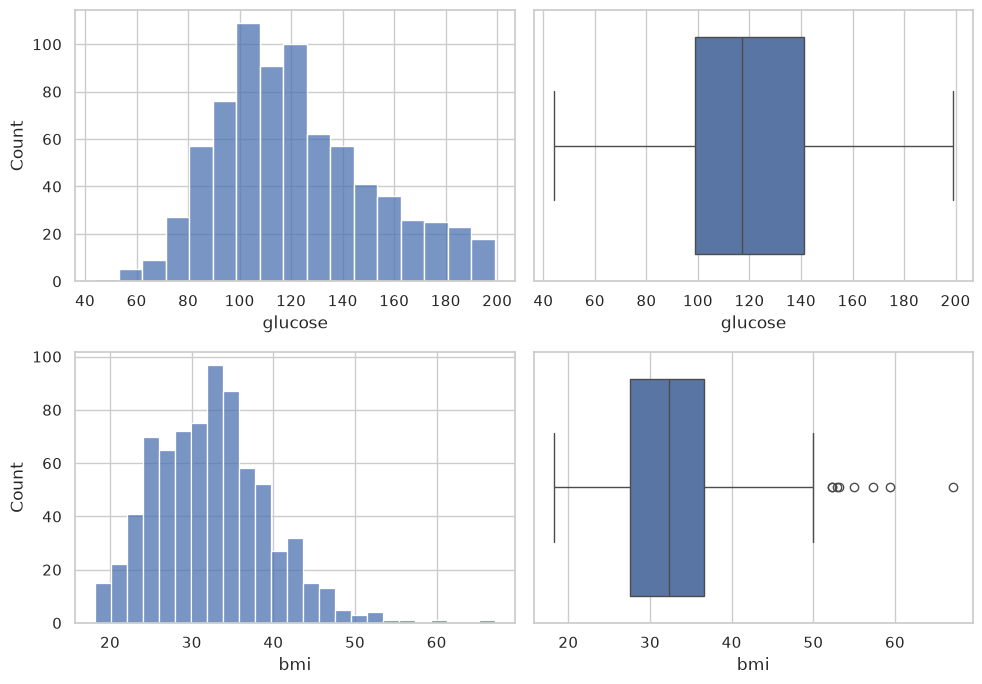

In [3]:
clean = frame.copy()
clean[["glucose","bmi"]] = clean[["glucose","bmi"]].replace(0,np.nan)
fig, axes = plt.subplots(2,2,figsize=(10,7))
for j,column in enumerate(["glucose","bmi"]):
    sns.histplot(clean[column],ax=axes[j,0]); sns.boxplot(x=clean[column],ax=axes[j,1])
fig.tight_layout()

## בדיקה ומשוב

בטרמינל משורש המאגר:

```bash
make check EX=03
```

כישלון עם `NotImplementedError` צפוי לפני השלמת הפונקציה. הצלחת הבדיקות מאמתת רק את חוזה הקוד; היא אינה ציון לאיכות הניתוח.

מחוון מתוך 10: קוד ובדיקות 4; גרפים וחקירה 2; מניעת הטיות/דליפה 2; פרשנות ומגבלות 2. יעד מעבר: 8 וכל בדיקות הקוד עוברות.

## דיון למורה

יש לבסס מסקנה על הפלט שהורץ. דרשי הבחנה בין קשר וסיבתיות, תיאור אוכלוסיית המדגם והערכת הכללה. אין מסקנה קלינית הנובעת מציון גבוה בלבד. בתרגיל 11 הדילול משנה את שכיחות האימון ולכן עלול לפגוע בהעברת הכיול לאוכלוסיית המבחן. בתרגיל 12 השווי ל־dummy ובחני עד כמה החלוקה הגאוגרפית משנה את ההמלצה. אין תשובה מילולית יחידה: השתמשי במחוון שבמחברת להערכת ההנמקה.